# Задание 3. ВВП по ППС и ожидаемая продолжительность жизни

Сначала сравним динамику ВВП на душу населения по ППС и места стран и
территорий. Затем проверим, насколько точно по ВВП и году можно оценить
ожидаемую продолжительность жизни.

Задача — регрессия. 

In [2]:
# Библиотеки
from pathlib import Path

from IPython.display import display

%matplotlib inline

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import SplineTransformer, StandardScaler
from sklearn.tree import DecisionTreeRegressor

In [3]:
# Настройки отчёта
BASE_DIRECTORY = Path.cwd()

LAST_TRAIN_YEAR = 2015
GDP_LABEL = "ВВП на душу по ППС, ед. файла"
LIFE_LABEL = "Ожидаемая продолжительность жизни, лет"
ECONOMY_LABEL = "Страна или территория"
INPUTS = ["gdp_ppp", "log_gdp", "year"]
BLUE, GREEN, RED = "#2769A3", "#007F73", "#C94A3D"

sns.set_theme(
    style="whitegrid",
    font="DejaVu Sans",
    rc={"axes.spines.top": False, "grid.alpha": 0.25},
)

In [4]:
# Вывод таблиц и графиков
def show_figure(fig, layout_rect=None):
    '''Показать график под ячейкой.'''
    fig.tight_layout(rect=layout_rect)
    plt.show()
    plt.close(fig)


def thousands(value, _position):
    return f"{value / 1000:g} тыс." if value >= 1000 else f"{value:g}"


def format_gdp_axis(axis):
    """Настроить логарифмическую шкалу ВВП и показать деления в единицах файла."""
    axis.set(xscale="log", xlabel=GDP_LABEL + " (лог. шкала)")
    axis.set_xticks([1000, 3000, 10000, 30000, 100000])
    axis.xaxis.set_major_formatter(FuncFormatter(thousands))

## 1. Качество данных и пропуски

Единица наблюдения — экономика в конкретном году. Для моделей берём строки
с известным ВВП. В описании целевой переменной используем все наблюдения.
Средние и медианы по экономикам считаем с равными весами.

In [5]:
# Загрузка и проверка исходной таблицы
data = pd.read_csv(BASE_DIRECTORY / "39_worldbank.csv").sort_values(["iso3", "year"])
assert not data.duplicated(["iso3", "year"]).any()
assert data[["iso3", "year", "life"]].notna().all().all()
assert data["life"].between(0, 120).all() and data["gdp_ppp"].dropna().gt(0).all()

# Справочник хранится рядом с данными. Код остаётся ключом для объединения.
name_directory = pd.read_csv(BASE_DIRECTORY / "worldbank_economy_names_ru.csv")
economy_names = name_directory.set_index("iso3", verify_integrity=True)[ECONOMY_LABEL]
named_economies = data["iso3"].map(economy_names)
missing_names = data.loc[named_economies.isna(), "iso3"].unique()
if len(missing_names):
    raise ValueError(f"В справочнике нет названий для кодов {', '.join(missing_names)}")

data.insert(0, ECONOMY_LABEL, named_economies)
complete = data.dropna(subset=["gdp_ppp"]).copy()
complete["log_gdp"] = np.log(complete["gdp_ppp"])

print(
    f"Наблюдений {len(data)}, экономик {data.iso3.nunique()}, "
    f"годы {data.year.min()}–{data.year.max()}. Дубликатов ключа iso3–year нет."
)
quality = data[["iso3", "year", "gdp_ppp", "life"]].isna().sum().to_frame("Пропуски")
quality["Доля, %"] = 100 * quality["Пропуски"] / len(data)
display(quality.round(2))

Наблюдений 4557, экономик 217, годы 2000–2020. Дубликатов ключа iso3–year нет.


,Пропуски,"Доля, %"
iso3,0,0.00
year,0,0.00
gdp_ppp,431,9.46
life,0,0.00


ВВП отсутствует хотя бы раз у 25 экономик, во все годы — у 18. Полных строк 4126 из 4557 (90.5%).


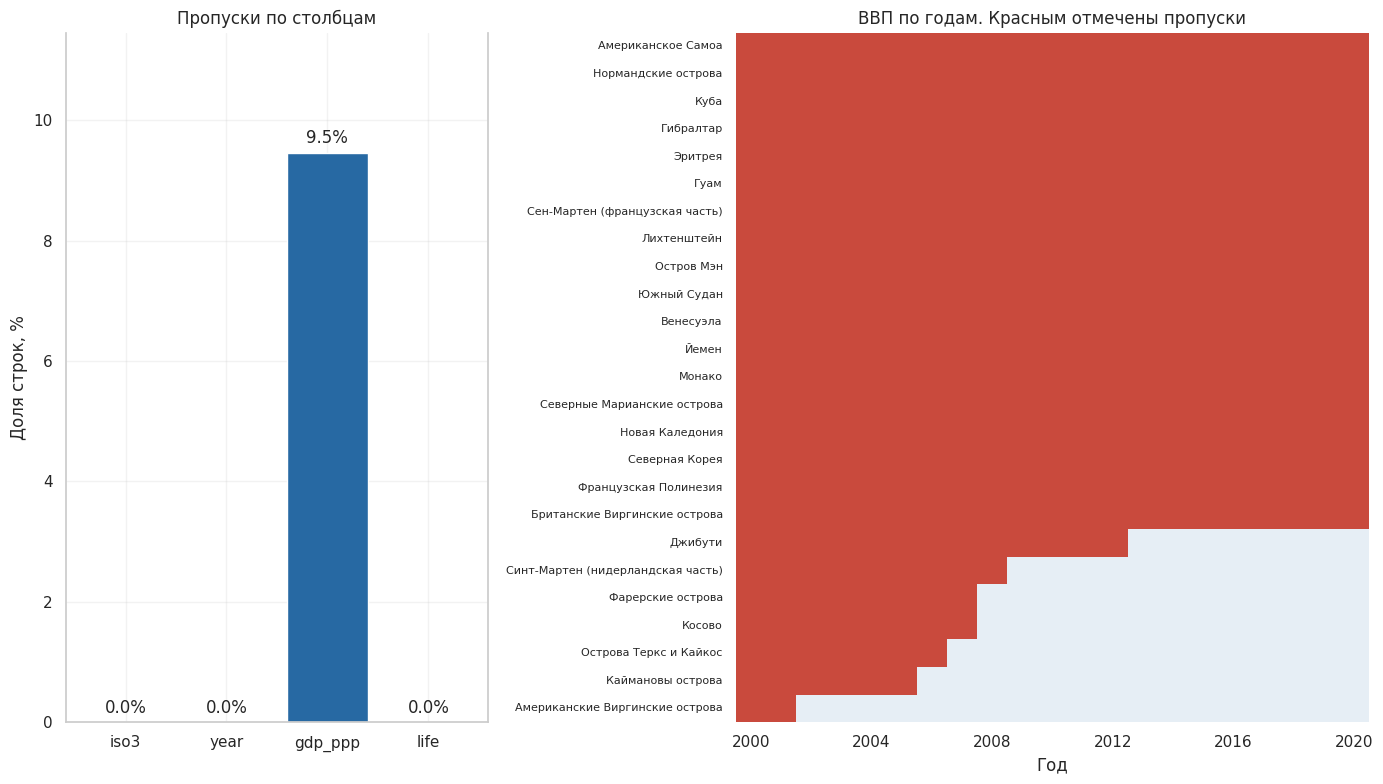

In [6]:
# Где сосредоточены пропуски ВВП
gdp_by_economy = data.pivot(index="iso3", columns="year", values="gdp_ppp")
gdp_panel = gdp_by_economy.dropna()

missing = gdp_by_economy.isna()
missing_counts = missing.sum(axis=1)
missing_codes = missing_counts[missing_counts > 0].sort_values(ascending=False).index
missing_grid = missing.loc[missing_codes].rename(index=economy_names)

print(
    f"ВВП отсутствует хотя бы раз у {len(missing_grid)} экономик, "
    f"во все годы — у {missing_grid.all(axis=1).sum()}. "
    f"Полных строк {len(complete)} из {len(data)} ({len(complete) / len(data):.1%})."
)

fig, axes = plt.subplots(1, 2, figsize=(14, 8), gridspec_kw={"width_ratios": [1, 1.5]})
axes[0].bar(quality.index, quality["Доля, %"], color=BLUE)
axes[0].set(title="Пропуски по столбцам", ylabel="Доля строк, %")
axes[0].bar_label(axes[0].containers[0], fmt="%.1f%%", padding=4)
axes[0].set_ylim(0, quality["Доля, %"].max() + 2)
sns.heatmap(
    missing_grid.astype(int), cmap=["#E6EEF5", RED], cbar=False,
    xticklabels=4, yticklabels=True, ax=axes[1],
)
axes[1].tick_params(axis="y", labelsize=8)
axes[1].set(title="ВВП по годам. Красным отмечены пропуски", xlabel="Год", ylabel="")
show_figure(fig)

## 2. Распределения и крайние наблюдения


,gdp_ppp,life
count,4126.00,4557.00
mean,23289.08,70.60
std,25117.54,8.91
min,702.85,14.66
25%,4919.28,65.03
50%,13884.11,72.45
75%,34275.00,77.26
max,174569.52,86.15


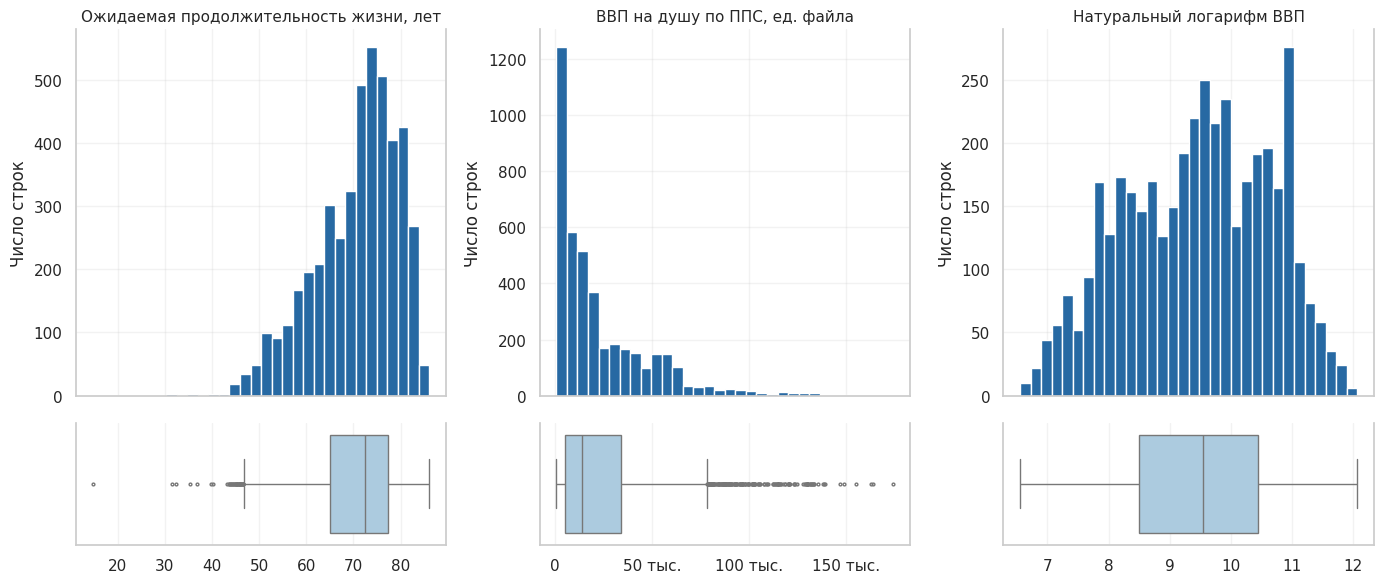

In [7]:
# Гистограммы и диаграммы размаха
display(data[["gdp_ppp", "life"]].describe().round(2))
fig, axes = plt.subplots(2, 3, figsize=(14, 6), gridspec_kw={"height_ratios": [3, 1]})
for col, (key, label) in enumerate([
    ("life", LIFE_LABEL), ("gdp_ppp", GDP_LABEL), ("log_gdp", "Натуральный логарифм ВВП"),
]):
    values = complete[key] if key == "log_gdp" else data[key].dropna()
    axes[0, col].hist(values, bins=32, color=BLUE, edgecolor="white")
    axes[0, col].set_title(label, fontsize=11)
    axes[0, col].set_ylabel("Число строк")
    sns.boxplot(x=values, ax=axes[1, col], color="#A4CDE7", fliersize=2)
    axes[1, col].set_xlabel("")
    axes[0, col].sharex(axes[1, col])
    axes[0, col].tick_params(labelbottom=False)
axes[1, 1].xaxis.set_major_locator(MaxNLocator(nbins=4))
axes[1, 1].xaxis.set_major_formatter(FuncFormatter(thousands))
show_figure(fig)

In [8]:
# Наблюдения за пределами 1,5 IQR
for column in ["gdp_ppp", "life"]:
    q1, q3 = data[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    flags = (data[column] < q1 - 1.5 * iqr) | (data[column] > q3 + 1.5 * iqr)
    print(f"{column} — за границами 1,5 IQR {flags.sum()} из {data[column].count()} строк.")
print("Самые низкие значения продолжительности жизни и самые высокие значения ВВП")
eda_columns = [ECONOMY_LABEL, "year", "gdp_ppp", "life"]
display(data.nsmallest(5, "life")[eda_columns].round(2))
display(data.nlargest(5, "gdp_ppp")[eda_columns].round(2))

gdp_ppp — за границами 1,5 IQR 170 из 4126 строк.
life — за границами 1,5 IQR 40 из 4557 строк.
Самые низкие значения продолжительности жизни и самые высокие значения ВВП


,Страна или территория,year,gdp_ppp,life
788,Центральноафриканская Республика,2009,1402.68,14.66
778,Центральноафриканская Республика,2019,1145.10,31.53
3705,Сомали,2011,1054.36,32.45
3741,Южный Судан,2017,NaN,35.35
3742,Южный Судан,2016,NaN,36.72


,Страна или территория,year,gdp_ppp,life
2464,Макао,2013,174569.52,82.72
2465,Макао,2012,164239.26,82.47
2463,Макао,2014,162813.44,83.02
2466,Макао,2011,155385.32,82.47
3348,Катар,2011,149025.12,79.99


## 3. Динамика и связь показателей


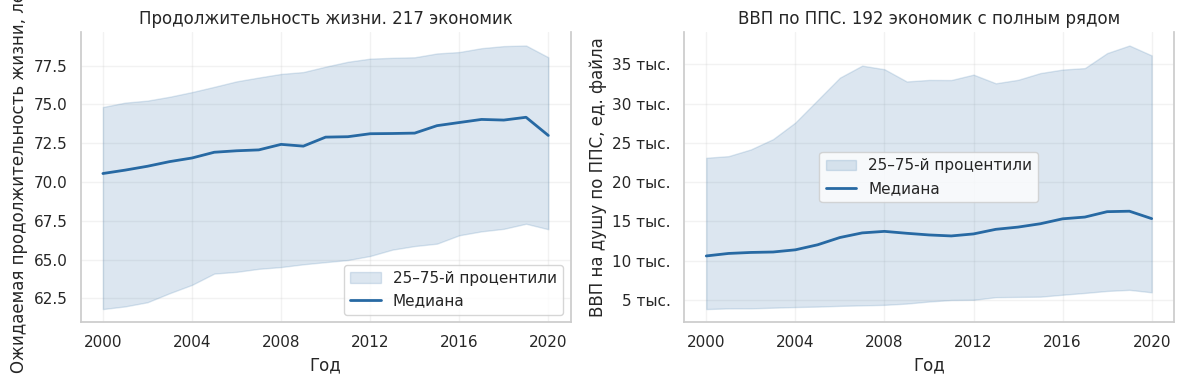

Медиана продолжительности жизни в 2000, 2019 и 2020 годах — 70.54, 74.17 и 72.99 года. В 2020 показатель снизился у 152 из 217 экономик.


In [9]:
# Медианы и квартильные диапазоны по годам
balanced = complete.loc[complete["iso3"].isin(gdp_panel.index)].copy()
life_trends = data.groupby("year")["life"].quantile([0.25, 0.5, 0.75]).unstack()
gdp_trends = balanced.groupby("year")["gdp_ppp"].quantile([0.25, 0.5, 0.75]).unstack()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, bands, label in zip(axes, [life_trends, gdp_trends], [LIFE_LABEL, GDP_LABEL]):
    axis.fill_between(
        bands.index,
        bands[0.25],
        bands[0.75],
        color=BLUE,
        alpha=0.16,
        label="25–75-й процентили",
    )
    axis.plot(bands.index, bands[0.5], color=BLUE, linewidth=2, label="Медиана")
    axis.set(xlabel="Год", ylabel=label)
    axis.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))
    axis.legend(loc="best")
axes[0].set_title(f"Продолжительность жизни. {data.iso3.nunique()} экономик")
axes[1].set_title(f"ВВП по ППС. {balanced.iso3.nunique()} экономик с полным рядом")
axes[1].yaxis.set_major_formatter(FuncFormatter(thousands))
show_figure(fig)

declines = data.pivot(index="iso3", columns="year", values="life").diff(axis=1)[2020]
median_life = life_trends[0.5]
print(
    "Медиана продолжительности жизни в 2000, 2019 и 2020 годах — "
    f"{median_life[2000]:.2f}, {median_life[2019]:.2f} и {median_life[2020]:.2f} года. "
    f"В 2020 показатель снизился у {(declines < 0).sum()} из {len(declines)} экономик."
)

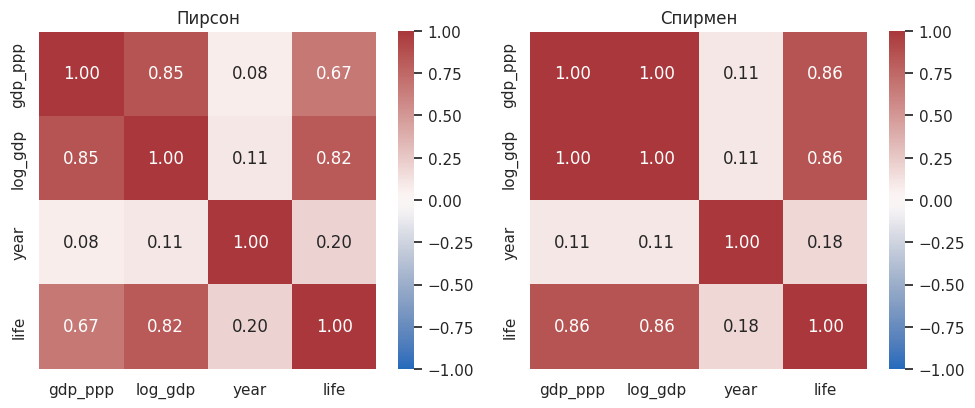

In [10]:
# Корреляции Пирсона и Спирмена
correlation_data = complete[["gdp_ppp", "log_gdp", "year", "life"]]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for method, title, axis in zip(["pearson", "spearman"], ["Пирсон", "Спирмен"], axes):
    sns.heatmap(
        correlation_data.corr(method=method),
        annot=True, fmt=".2f", center=0, vmin=-1, vmax=1,
        cmap="vlag", square=True, ax=axis,
    )
    axis.set_title(title)
show_figure(fig)

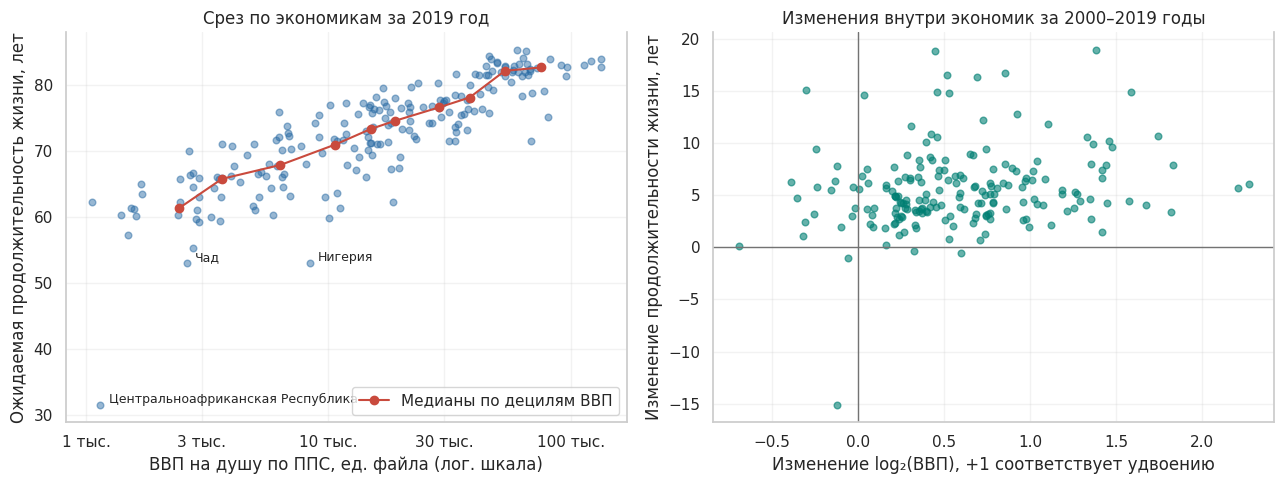

In [11]:
# Связь между экономиками и изменения внутри них
snapshot = complete.loc[complete["year"] == 2019]
# Группируем срез по децилям ВВП. Медианы показывают форму зависимости.
deciles = pd.qcut(snapshot["gdp_ppp"], 10)
snapshot_medians = snapshot.groupby(deciles, observed=True)[["gdp_ppp", "life"]].median()
start = balanced.loc[balanced["year"] == 2000].set_index("iso3")
end = balanced.loc[balanced["year"] == 2019].set_index("iso3")
changes = pd.DataFrame({
    "gdp_change": (end["log_gdp"] - start["log_gdp"]) / np.log(2),
    "life_change": end["life"] - start["life"],
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(snapshot["gdp_ppp"], snapshot["life"], color=BLUE, alpha=0.48, s=23)
axes[0].plot(
    snapshot_medians["gdp_ppp"], snapshot_medians["life"],
    color=RED, marker="o", label="Медианы по децилям ВВП",
)
axes[0].set(ylabel=LIFE_LABEL, title="Срез по экономикам за 2019 год")
format_gdp_axis(axes[0])
axes[0].legend(loc="lower right")
for _, row in snapshot.nsmallest(3, "life").iterrows():
    axes[0].annotate(
        row[ECONOMY_LABEL], (row["gdp_ppp"], row["life"]),
        xytext=(6, 1), textcoords="offset points", fontsize=9,
    )

axes[1].scatter(changes["gdp_change"], changes["life_change"], color=GREEN, alpha=0.6, s=23)
axes[1].axhline(0, color="0.45", linewidth=1)
axes[1].axvline(0, color="0.45", linewidth=1)
axes[1].set(
    title="Изменения внутри экономик за 2000–2019 годы",
    xlabel="Изменение log₂(ВВП), +1 соответствует удвоению",
    ylabel="Изменение продолжительности жизни, лет",
)
show_figure(fig)

## 4. Как менялись экономики и их места в рейтинге


In [13]:
# Места и годовые изменения для каждой экономики
first_year = int(gdp_panel.columns[0])
last_year = int(gdp_panel.columns[-1])
previous_year = last_year - 1

annual_rank_label = "Место среди всех с ВВП"
panel_rank_label = "Место в постоянной группе"

annual_rankings = data[[ECONOMY_LABEL, "iso3", "year", "gdp_ppp"]].copy()
annual_rankings["Экономик с ВВП в этом году"] = (
    annual_rankings.groupby("year")["gdp_ppp"].transform("count")
)
annual_rankings[annual_rank_label] = (
    annual_rankings.groupby("year")["gdp_ppp"]
    .rank(ascending=False, method="min")
    .astype("Int64")
)
panel_rows = annual_rankings["iso3"].isin(gdp_panel.index)
annual_rankings[panel_rank_label] = (
    annual_rankings.loc[panel_rows].groupby("year")["gdp_ppp"]
    .rank(ascending=False, method="min")
    .astype("Int64")
)
annual_rankings["Изменение ВВП за год, %"] = (
    annual_rankings.groupby("iso3")["gdp_ppp"].pct_change(fill_method=None) * 100
)
annual_rankings["Подъём за год в постоянной группе"] = (
    -annual_rankings.groupby("iso3")[panel_rank_label].diff()
)

annual_leaders = (
    annual_rankings.loc[annual_rankings[annual_rank_label] <= 5]
    .groupby(["year", annual_rank_label])[ECONOMY_LABEL]
    .agg(" / ".join)
    .unstack()
)
print("Первые пять мест каждого года среди всех экономик с доступным ВВП")
display(annual_leaders)

Первые пять мест каждого года среди всех экономик с доступным ВВП


Место среди всех с ВВП,1,2,3,4,5
year,,,,,
2000,Люксембург,Бруней,Катар,Бермуды,ОАЭ
2001,Люксембург,Бермуды,Бруней,Катар,ОАЭ
2002,Люксембург,Бермуды,Бруней,Катар,ОАЭ
2003,Люксембург,Бермуды,Бруней,Катар,ОАЭ
2004,Люксембург,Катар,Бермуды,Бруней,ОАЭ
2005,Люксембург,Катар,Бермуды,Бруней,ОАЭ
2006,Люксембург,Катар,Бермуды,Бруней,ОАЭ
2007,Люксембург,Бермуды,Катар,Макао,Бруней
2008,Люксембург,Бермуды,Катар,Макао,Бруней


### Места выбранной страны или территории по годам

In [14]:
# Годовые места выбранной экономики
selected_economy = "Россия"
economy_history = annual_rankings.loc[annual_rankings[ECONOMY_LABEL] == selected_economy]
if economy_history.empty:
    print(f"В данных нет экономики с названием «{selected_economy}».")
else:
    display(economy_history.drop(columns="iso3").set_index("year").round(2))

,Страна или территория,gdp_ppp,Экономик с ВВП в этом году,Место среди всех с ВВП,Место в постоянной группе,"Изменение ВВП за год, %",Подъём за год в постоянной группе
year,,,,,,,
2000,Россия,20104.75,192,57,57,NaN,<NA>
2001,Россия,21219.90,192,53,53,5.55,4
2002,Россия,22319.68,193,53,52,5.18,1
2003,Россия,24057.93,193,54,53,7.79,-1
2004,Россия,25894.15,193,55,54,7.63,-1
2005,Россия,27656.66,193,54,53,6.81,1
2006,Россия,30022.67,194,54,52,8.55,1
2007,Россия,32630.37,195,54,52,8.69,0
2008,Россия,34342.23,197,52,49,5.25,3


In [15]:
# Изменение ВВП и места за весь период и за последний год
panel_ranks = gdp_panel.rank(axis=0, ascending=False, method="min").astype(int)
first_rank = f"Место {first_year}"
previous_rank = f"Место {previous_year}"
last_rank = f"Место {last_year}"
rank_gain = f"Подъём мест {first_year}–{last_year}"
recent_rank_gain = f"Подъём мест {previous_year}–{last_year}"
gdp_growth = f"Изменение ВВП {first_year}–{last_year}, %"
recent_gdp_growth = f"Изменение ВВП {previous_year}–{last_year}, %"

economy_summary = pd.DataFrame({
    ECONOMY_LABEL: economy_names.reindex(gdp_panel.index),
    first_rank: panel_ranks[first_year],
    previous_rank: panel_ranks[previous_year],
    last_rank: panel_ranks[last_year],
    rank_gain: panel_ranks[first_year] - panel_ranks[last_year],
    recent_rank_gain: panel_ranks[previous_year] - panel_ranks[last_year],
    f"ВВП {last_year}": gdp_panel[last_year],
    gdp_growth: 100 * (gdp_panel[last_year] / gdp_panel[first_year] - 1),
    recent_gdp_growth: 100 * (gdp_panel[last_year] / gdp_panel[previous_year] - 1),
})

Наибольшие сдвиги мест за 2000–2020 годы


,Место 2000,Место 2020,Подъём мест 2000–2020,"Изменение ВВП 2000–2020, %"
Страна или территория,,,,
Ливия,65,121,-56,-43.8
Сирия,109,154,-45,-39.7
Барбадос,52,91,-39,-23.1
Зимбабве,119,156,-37,-26.6
Габон,51,82,-31,-14.0
Грузия,125,88,37,198.5
Армения,136,98,38,228.0
Мьянма,183,145,38,335.8
Азербайджан,126,80,46,238.1


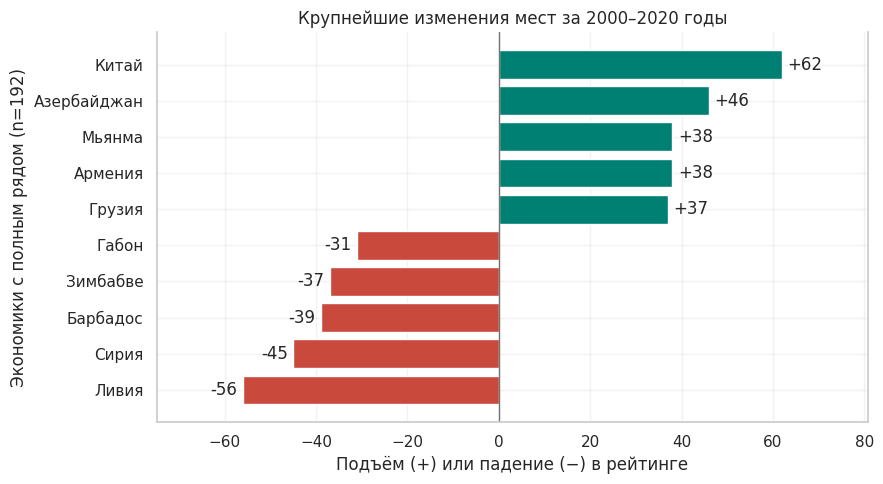

In [16]:
# Самые крупные подъёмы и падения в рейтинге
biggest_gains = economy_summary.nlargest(5, rank_gain)
biggest_losses = economy_summary.nsmallest(5, rank_gain)
rank_movers = pd.concat([biggest_gains, biggest_losses]).sort_values(rank_gain)

print(f"Наибольшие сдвиги мест за {first_year}–{last_year} годы")
rank_columns = [first_rank, last_rank, rank_gain, gdp_growth]
display(rank_movers.set_index(ECONOMY_LABEL)[rank_columns].round(1))

fig, axis = plt.subplots(figsize=(9, 5))
rank_colors = np.where(rank_movers[rank_gain] > 0, GREEN, RED)
bars = axis.barh(rank_movers[ECONOMY_LABEL], rank_movers[rank_gain], color=rank_colors)
axis.bar_label(bars, fmt="%+d", padding=4)
axis.axvline(0, color="0.45", linewidth=1)
axis.margins(x=0.16)
axis.set(
    title=f"Крупнейшие изменения мест за {first_year}–{last_year} годы",
    xlabel="Подъём (+) или падение (−) в рейтинге",
    ylabel=f"Экономики с полным рядом (n={len(gdp_panel)})",
)
show_figure(fig)

### Две группы для сравнения

В первой — экономики с рекордами по изменению ВВП или места. Во второй —
США, Китай, Германия, Япония, Индия и Россия как примеры крупных экономик
по общему ВВП. 


In [17]:
# Общие шкалы для графиков траекторий
def plot_economy_trajectories(labels, title):
    """Показать место и индекс ВВП одних и тех же стран."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.8))
    fig.suptitle(title, fontsize=15)
    colors = ["#2769A3", "#C94A3D", "#007F73", "#8558A6", "#C78A12", "#566573"]

    for (code, label), color in zip(labels.items(), colors):
        axes[0].plot(
            panel_ranks.columns, panel_ranks.loc[code],
            label=label, color=color, linewidth=2.1,
        )
        axes[1].plot(
            gdp_index.columns, gdp_index.loc[code],
            color=color, linewidth=2.1,
        )

    axes[0].set(
        title=f"Место среди {len(gdp_panel)} экономик",
        ylabel="Место (1 — самое высокое)",
        ylim=(len(gdp_panel) + 2, 0),
        yticks=[1, *range(25, len(gdp_panel) + 1, 25)],
    )
    axes[1].set(
        title="Изменение уровня ВВП на душу по ППС",
        ylabel=f"Индекс ВВП ({first_year} год = 100)",
    )
    axes[1].axhline(100, color="0.6", linewidth=1, linestyle=":")

    for axis in axes:
        axis.axvspan(previous_year, last_year, color="0.5", alpha=0.1, linewidth=0)
        axis.set_xlabel("Год")
        axis.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=6))

    handles, legend_labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, legend_labels, loc="lower center", ncol=2, fontsize=10)
    show_figure(fig, layout_rect=(0, 0.15, 1, 1))


gdp_index = gdp_panel.div(gdp_panel[first_year], axis=0) * 100

ВВП и места экономик с наибольшими изменениями


,Место 2000,Место 2019,Место 2020,Подъём мест 2000–2020,Подъём мест 2019–2020,ВВП 2020,"Изменение ВВП 2000–2020, %","Изменение ВВП 2019–2020, %"
Страна или территория,,,,,,,,
Китай,141,85,79,62,6,19215.1,372.6,2.1
Ливия,65,111,121,-56,-10,9978.7,-43.8,-30.4
Гайана,108,113,78,30,35,19234.1,139.7,43.5
Макао,14,1,18,-4,-17,59662.5,6.6,-55.3
Мальдивы,78,75,103,-25,-28,14243.0,3.7,-34.8


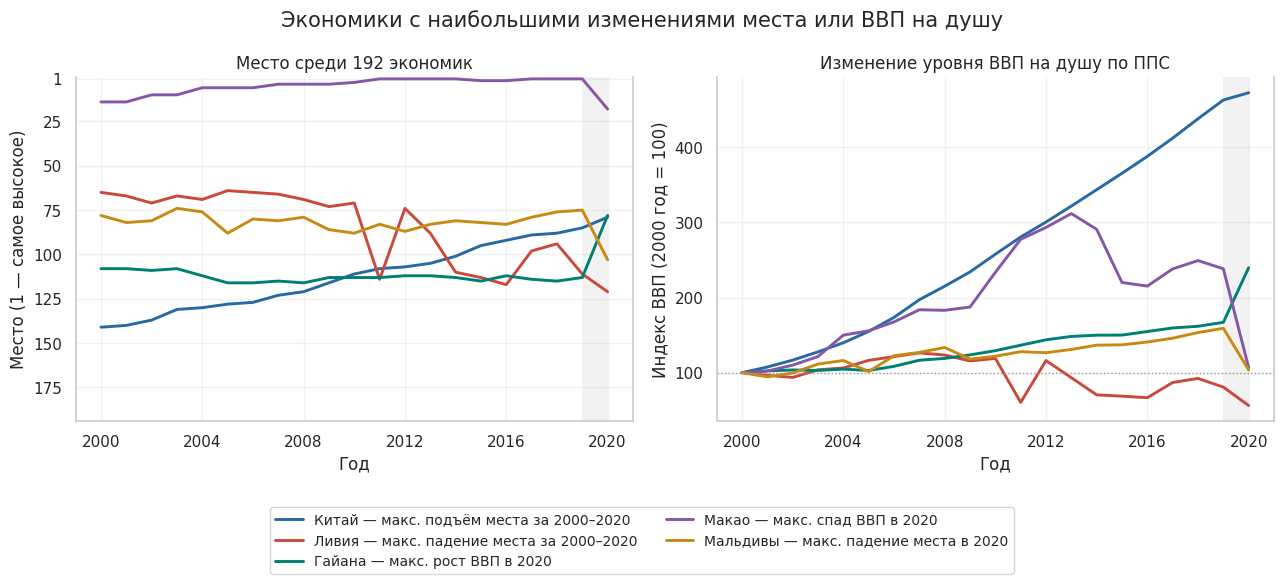

In [18]:
# Экономики с наибольшими изменениями
case_criteria = [
    (economy_summary[rank_gain].idxmax(), f"макс. подъём места за {first_year}–{last_year}"),
    (economy_summary[rank_gain].idxmin(), f"макс. падение места за {first_year}–{last_year}"),
    (economy_summary[recent_gdp_growth].idxmax(), f"макс. рост ВВП в {last_year}"),
    (economy_summary[recent_gdp_growth].idxmin(), f"макс. спад ВВП в {last_year}"),
    (economy_summary[recent_rank_gain].idxmin(), f"макс. падение места в {last_year}"),
]
case_labels = {}
for code, criterion in case_criteria:
    case_labels.setdefault(code, f"{economy_names.at[code]} — {criterion}")

print("ВВП и места экономик с наибольшими изменениями")
display(economy_summary.loc[list(case_labels)].set_index(ECONOMY_LABEL).round(1))
plot_economy_trajectories(
    case_labels,
    "Экономики с наибольшими изменениями места или ВВП на душу",
)

ВВП и места выбранных крупных экономик


,Место 2000,Место 2019,Место 2020,Подъём мест 2000–2020,Подъём мест 2019–2020,ВВП 2020,"Изменение ВВП 2000–2020, %","Изменение ВВП 2019–2020, %"
Страна или территория,,,,,,,,
США,16,11,10,6,1,67406.8,22.5,-2.5
Китай,141,85,79,62,6,19215.1,372.6,2.1
Германия,23,19,16,7,3,60299.6,20.7,-4.2
Япония,34,37,36,-2,1,44212.6,11.3,-4.0
Индия,158,134,134,24,0,7186.9,138.7,-6.7
Россия,57,49,47,10,2,36376.3,80.9,-2.5


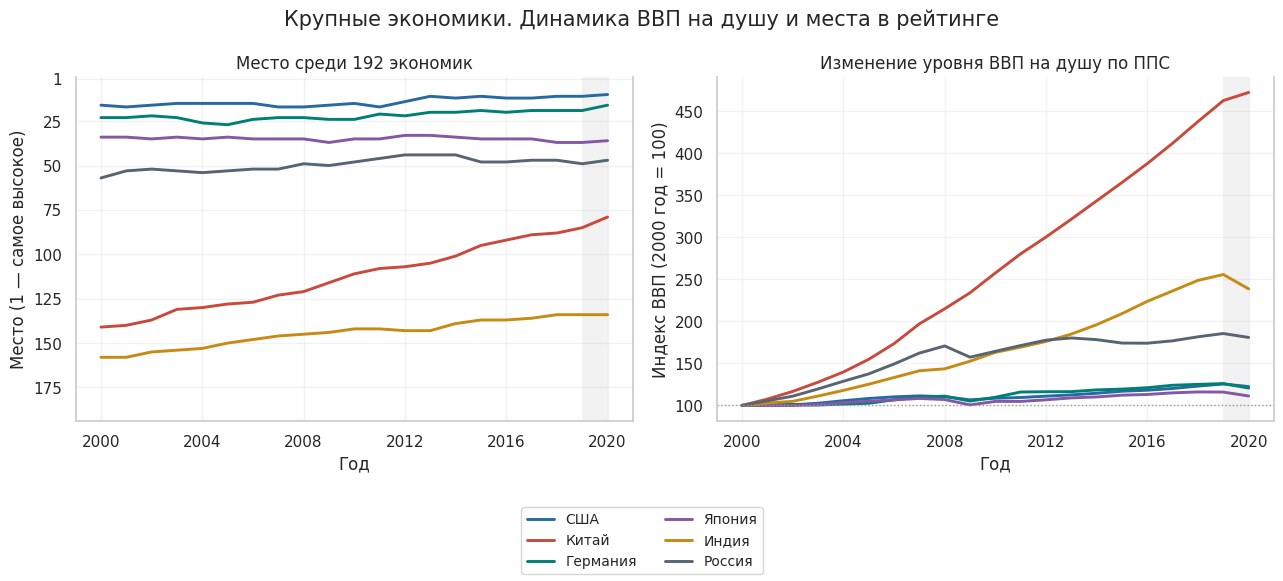

In [19]:
# Динамика выбранных крупных экономик
benchmark_codes = ["USA", "CHN", "DEU", "JPN", "IND", "RUS"]
benchmark_labels = economy_names.loc[benchmark_codes].to_dict()

print("ВВП и места выбранных крупных экономик")
display(economy_summary.loc[benchmark_codes].set_index(ECONOMY_LABEL).round(1))
plot_economy_trajectories(
    benchmark_labels,
    "Крупные экономики. Динамика ВВП на душу и места в рейтинге",
)

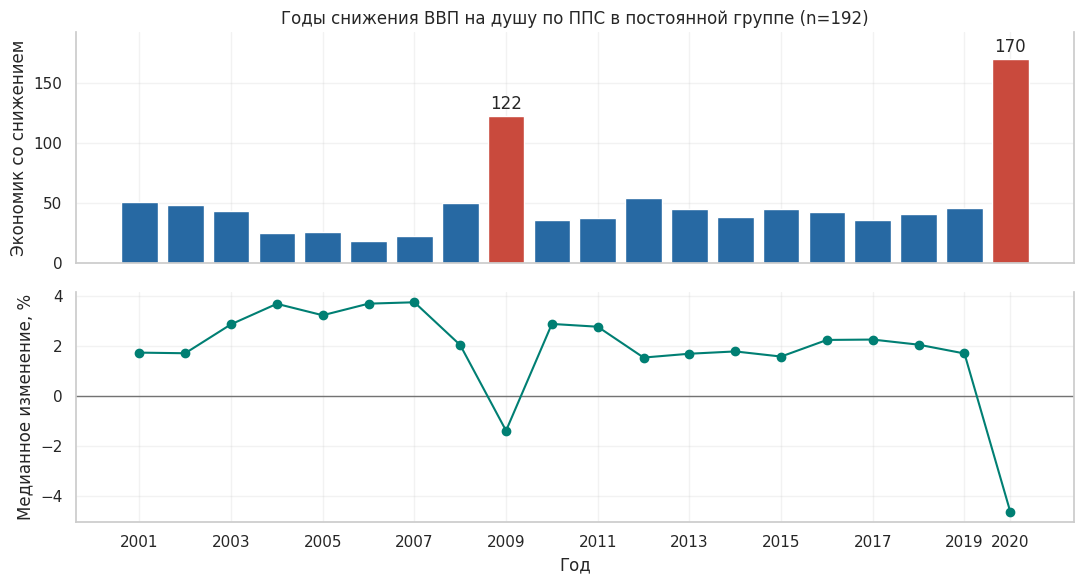

Годы, когда ВВП на душу снизился у наибольшего числа экономик


,Экономик со снижением,"Медианное изменение, %"
year,,
2020,170,-4.62
2009,122,-1.38


In [20]:
# В какие годы снижение ВВП было наиболее распространённым
annual_growth = gdp_panel.pct_change(axis=1, fill_method=None).iloc[:, 1:] * 100
economies_with_decline = annual_growth.lt(0).sum(axis=0)
median_growth = annual_growth.median(axis=0)
most_declines = economies_with_decline.nlargest(2)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
year_colors = np.where(economies_with_decline.index.isin(most_declines.index), RED, BLUE)
axes[0].bar(economies_with_decline.index, economies_with_decline, color=year_colors)
for year, count in most_declines.items():
    axes[0].annotate(
        str(count), (year, count), xytext=(0, 5), textcoords="offset points",
        ha="center",
    )
axes[0].set(
    title=f"Годы снижения ВВП на душу по ППС в постоянной группе (n={len(gdp_panel)})",
    ylabel="Экономик со снижением",
    ylim=(0, len(gdp_panel)),
)
axes[1].axhline(0, color="0.45", linewidth=1)
axes[1].plot(median_growth.index, median_growth, color=GREEN, marker="o")
axes[1].set(xlabel="Год", ylabel="Медианное изменение, %")
axes[1].set_xticks(annual_growth.columns[::2].union(pd.Index([last_year])))
show_figure(fig)

print("Годы, когда ВВП на душу снизился у наибольшего числа экономик")
display(pd.DataFrame({
    "Экономик со снижением": most_declines,
    "Медианное изменение, %": median_growth.loc[most_declines.index].round(2),
}))

**Выводы по ВВП.** Китай поднялся со 141-го на 79-е место, Ливия опустилась
с 65-го на 121-е. В 2020 году Гайана поднялась со 113-го на 78-е место,
а Макао потерял первое место и оказался на 18-м. Наибольшее падение места
за этот год было у Мальдив (75-е → 103-е).

ВВП на душу России за 2019–2020 годы снизился на 2,5%, хотя место выросло
с 49-го до 47-го. В 2020 году снижение наблюдалось у 170 из 192 экономик,
в 2009-м — у 122. Эти сравнения описывают динамику в пределах датасета.

## 5. Контрольные выборки и сравнение моделей

До 2015 года включительно обучаемся на 80% экономик с доступным ВВП.
Остальные экономики с ВВП случайно отложены целиком с фиксированным seed.
Два теста используют 2016–2020
годы: один для знакомых экономик, второй для отложенных.
На обучении используем три последовательные проверки с расширением периода.
Модель и параметры выбираем по средней MAE этих проверок.

In [21]:
# Разделение по экономикам и годам
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
known_indices, _ = next(splitter.split(complete, groups=complete["iso3"]))
known_countries = set(complete.iloc[known_indices]["iso3"])
known_mask = complete["iso3"].isin(known_countries)
early_mask = complete["year"] <= LAST_TRAIN_YEAR

train = complete.loc[known_mask & early_mask]
tests = {
    "Знакомые экономики": complete.loc[known_mask & ~early_mask],
    "Отложенные экономики": complete.loc[~known_mask & ~early_mask],
}

assert set(train["iso3"]).isdisjoint(tests["Отложенные экономики"]["iso3"])
assert set(tests["Знакомые экономики"]["iso3"]).issubset(train["iso3"])
assert all(train["year"].max() < test["year"].min() for test in tests.values())


def split_row(part, frame):
    return {
        "Часть": part,
        "Строк": len(frame),
        "Экономик": frame["iso3"].nunique(),
        "Годы": f"{frame.year.min()}–{frame.year.max()}",
    }


split_summary = [split_row("Обучение", train)]
split_summary.extend(split_row(part, test) for part, test in tests.items())
display(pd.DataFrame(split_summary))

latest = data.loc[data["year"] > LAST_TRAIN_YEAR]
covered_rows = sum(len(test) for test in tests.values())
missing_economies = latest.loc[latest["gdp_ppp"].isna(), "iso3"].nunique()
print(
    f"Охват поздних лет — {covered_rows} из {len(latest)} строк. "
    f"У {missing_economies} экономик в этот период отсутствует ВВП."
)

,Часть,Строк,Экономик,Годы
0,Обучение,2498,159,2000–2015
1,Знакомые экономики,795,159,2016–2020
2,Отложенные экономики,200,40,2016–2020


Охват поздних лет — 995 из 1085 строк. У 18 экономик в этот период отсутствует ВВП.


In [22]:
# Временные фолды внутри обучающего периода
validation_windows = [(2007, 2009), (2010, 2012), (2013, 2015)]
cv_splits = []
cv_summary = []

for start_year, end_year in validation_windows:
    fit_indices = np.flatnonzero(train["year"] < start_year)
    validation_indices = np.flatnonzero(train["year"].between(start_year, end_year))
    cv_splits.append((fit_indices, validation_indices))
    cv_summary.append({
        "Обучение по год": start_year - 1,
        "Проверка": f"{start_year}–{end_year}",
        "Строк в обучении": len(fit_indices),
        "Строк в проверке": len(validation_indices),
    })

display(pd.DataFrame(cv_summary))

,Обучение по год,Проверка,Строк в обучении,Строк в проверке
0,2006,2007–2009,1077,470
1,2009,2010–2012,1547,474
2,2012,2013–2015,2021,477


In [23]:
# Модель на четырёх диапазонах ВВП
class IncomeBands(RegressorMixin, BaseEstimator):
    """Четыре диапазона ВВП с отдельным прогнозом-медианой."""

    def fit(self, X, y):
        gdp_quartiles = X["gdp_ppp"].quantile([0.25, 0.5, 0.75]).to_numpy()
        self.thresholds_ = np.round(gdp_quartiles, -3)

        bands = np.searchsorted(self.thresholds_, X["gdp_ppp"], side="right")
        medians = pd.Series(np.asarray(y)).groupby(bands).median()
        overall_median = float(np.median(y))
        self.medians_ = medians.reindex(range(4), fill_value=overall_median).to_numpy()
        return self

    def predict(self, X):
        bands = np.searchsorted(self.thresholds_, X["gdp_ppp"], side="right")
        return self.medians_[bands]

In [24]:
# Модели и сетки параметров
def select_columns(columns):
    return ColumnTransformer([("values", "passthrough", columns)])


smooth_inputs = ColumnTransformer([
    ("curve", SplineTransformer(knots="quantile", extrapolation="linear"), ["log_gdp"]),
    ("time", StandardScaler(), ["year"]),
])
models = {
    "Медиана": (DummyRegressor(strategy="median"), {}),
    "Диапазоны ВВП": (IncomeBands(), {}),
    "Линейная, ВВП": (
        make_pipeline(select_columns(["gdp_ppp"]), LinearRegression()),
        {},
    ),
    "Линейная, ВВП + год": (
        make_pipeline(select_columns(["gdp_ppp", "year"]), LinearRegression()),
        {},
    ),
    "Линейная, log ВВП + год": (
        make_pipeline(select_columns(["log_gdp", "year"]), LinearRegression()),
        {},
    ),
    "Сплайн, log ВВП + год": (
        make_pipeline(smooth_inputs, Ridge()),
        {
            "columntransformer__curve__n_knots": [3, 5, 8],
            "ridge__alpha": [0.1, 1, 10],
        },
    ),
    "Дерево": (
        make_pipeline(
            select_columns(["log_gdp", "year"]),
            DecisionTreeRegressor(random_state=42),
        ),
        {
            "decisiontreeregressor__max_depth": [2, 4, 6],
            "decisiontreeregressor__min_samples_leaf": [15, 40, 80],
        },
    ),
    "Градиентный бустинг": (
        make_pipeline(
            select_columns(["log_gdp", "year"]),
            HistGradientBoostingRegressor(random_state=42, early_stopping=False),
        ),
        {
            "histgradientboostingregressor__max_leaf_nodes": [7, 15],
            "histgradientboostingregressor__min_samples_leaf": [20, 60],
            "histgradientboostingregressor__max_iter": [100, 200],
        },
    ),
}

In [25]:
# Подбор параметров и выбор модели по MAE
fitted_models = {}
validation_results = []

for name, (estimator, grid) in models.items():
    search = GridSearchCV(
        estimator,
        grid,
        scoring="neg_mean_absolute_error",
        cv=cv_splits,
        error_score="raise",
    )
    search.fit(train[INPUTS], train["life"])
    fitted_models[name] = search.best_estimator_
    validation_results.append({
        "Модель": name,
        "MAE, лет": -search.best_score_,
        "Параметры": search.best_params_,
    })

validation = pd.DataFrame(validation_results).set_index("Модель").sort_values("MAE, лет")
winner_name = validation.index[0]
winner = fitted_models[winner_name]
print(f"Выбор по временной валидации — {winner_name}.")
display(validation.round(3))

Выбор по временной валидации — Градиентный бустинг.


,"MAE, лет",Параметры
Модель,,
Градиентный бустинг,3.405,{'histgradientboostingregressor__max_iter': 10...
"Сплайн, log ВВП + год",3.452,"{'columntransformer__curve__n_knots': 8, 'ridg..."
"Линейная, log ВВП + год",3.565,{}
Дерево,3.698,"{'decisiontreeregressor__max_depth': 6, 'decis..."
Диапазоны ВВП,3.733,{}
"Линейная, ВВП + год",5.125,{}
"Линейная, ВВП",5.456,{}
Медиана,6.751,{}


In [26]:
# Пороговые значения итоговой модели диапазонов
manual_model = fitted_models["Диапазоны ВВП"]
gdp_breaks = [-np.inf, *manual_model.thresholds_, np.inf]
ranges = pd.IntervalIndex.from_breaks(gdp_breaks, closed="left")
display(pd.DataFrame({
    "Диапазон ВВП": ranges.astype(str),
    "Прогноз жизни, лет": manual_model.medians_.round(2),
}))

,Диапазон ВВП,"Прогноз жизни, лет"
0,"[-inf, 5000.0)",59.96
1,"[5000.0, 15000.0)",70.72
2,"[15000.0, 35000.0)",73.82
3,"[35000.0, inf)",79.42


## 6. Проверка качества и разбор ошибок

MAE показывает среднюю ошибку в годах, RMSE сильнее реагирует на крупные
промахи, R² сравнивает ошибки со средним фактом внутри проверяемой части.
Модели сравниваются на одинаковых строках. Состав теста ограничен наличием ВВП.

In [27]:
# Метрики на знакомых и отложенных экономиках
test_results = []
predictions = []

for part, test in tests.items():
    for name, model in fitted_models.items():
        predicted = model.predict(test[INPUTS])
        residual = predicted - test["life"]
        test_results.append({
            "Модель": name, "Проверка": part,
            "MAE, лет": mean_absolute_error(test["life"], predicted),
            "RMSE, лет": np.sqrt(np.mean(residual**2)),
            "R²": r2_score(test["life"], predicted),
            "Смещение, лет": residual.mean(),
        })

        if name == winner_name:
            predictions.append(
                test.assign(Проверка=part, predicted=predicted, error=residual)
            )

scores = pd.DataFrame(test_results)
details = pd.concat(predictions)

display(scores.round(3))

,Модель,Проверка,"MAE, лет","RMSE, лет",R²,"Смещение, лет"
0,Медиана,Знакомые экономики,6.269,7.470,-0.007,-0.608
1,Диапазоны ВВП,Знакомые экономики,3.494,4.540,0.628,-0.694
2,"Линейная, ВВП",Знакомые экономики,4.727,5.568,0.441,-2.151
3,"Линейная, ВВП + год",Знакомые экономики,4.128,5.144,0.523,0.298
4,"Линейная, log ВВП + год",Знакомые экономики,2.989,3.944,0.719,0.202
5,"Сплайн, log ВВП + год",Знакомые экономики,2.948,3.965,0.716,0.255
6,Дерево,Знакомые экономики,3.135,4.067,0.702,-0.608
7,Градиентный бустинг,Знакомые экономики,2.910,3.778,0.743,-0.345
8,Медиана,Отложенные экономики,6.742,8.756,-0.037,1.646
9,Диапазоны ВВП,Отложенные экономики,3.583,4.732,0.697,-0.440


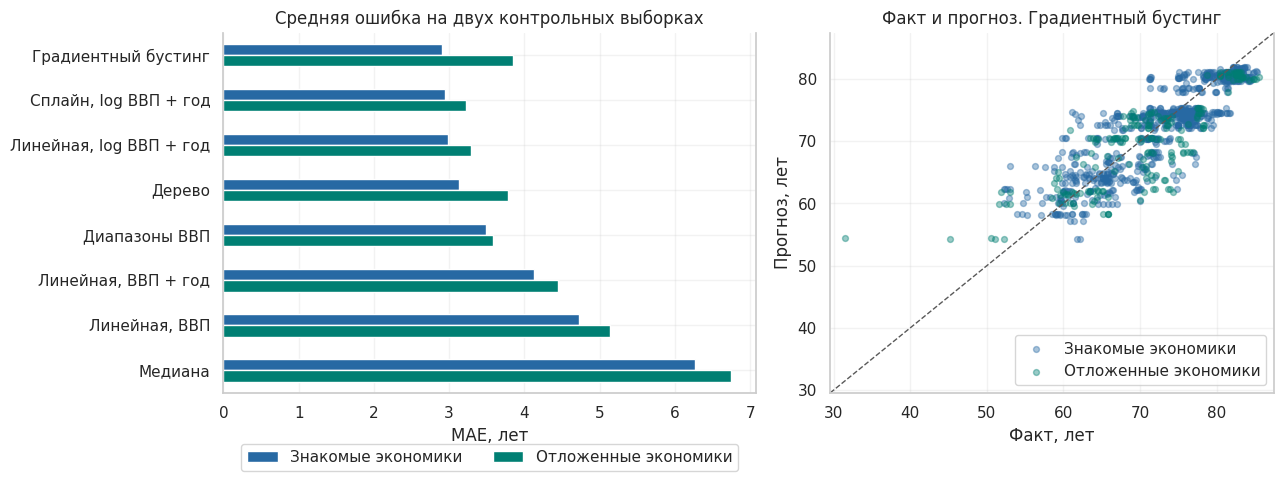

In [28]:
# Сравнение моделей и график факта против прогноза
palette = dict(zip(tests, [BLUE, GREEN]))
test_mae = scores.pivot(index="Модель", columns="Проверка", values="MAE, лет")
test_mae = test_mae.loc[validation.index, list(tests)]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.2, 1]})
test_mae.plot.barh(ax=axes[0], color=palette)
axes[0].invert_yaxis()
axes[0].set(title="Средняя ошибка на двух контрольных выборках", xlabel="MAE, лет", ylabel="")
axes[0].legend(title="", loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)

for part, rows in details.groupby("Проверка"):
    axes[1].scatter(
        rows["life"], rows["predicted"],
        s=18, alpha=0.4, color=palette[part], label=part,
    )

limits = [
    min(details["life"].min(), details["predicted"].min()) - 2,
    max(details["life"].max(), details["predicted"].max()) + 2,
]
axes[1].plot(limits, limits, color="0.35", linestyle="--", linewidth=1)
axes[1].set(
    title=f"Факт и прогноз. {winner_name}",
    xlabel="Факт, лет",
    ylabel="Прогноз, лет",
    xlim=limits,
    ylim=limits,
)
axes[1].legend(loc="lower right")
show_figure(fig)

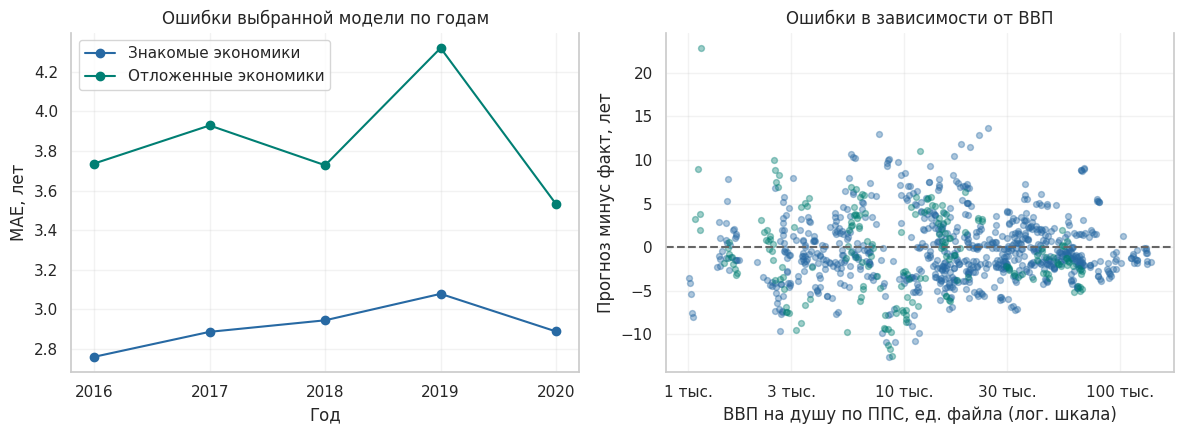

Пять крупнейших промахов выбранной модели


,Страна или территория,year,gdp_ppp,life,predicted,error,Проверка
778,Центральноафриканская Республика,2019,1145.10,31.53,54.38,22.85,Отложенные экономики
1264,Экваториальная Гвинея,2016,24435.06,61.08,74.73,13.65,Знакомые экономики
3024,Нигерия,2020,7664.21,53.07,66.07,13.00,Знакомые экономики
1263,Экваториальная Гвинея,2017,22250.44,61.48,74.36,12.88,Знакомые экономики
674,Кабо-Верде,2018,8531.13,74.84,62.26,-12.58,Знакомые экономики


In [29]:
# Ошибки по годам и уровням ВВП
year_mae = details.assign(abs_error=details["error"].abs()).pivot_table(
    index="year", columns="Проверка", values="abs_error", aggfunc="mean",
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
year_mae.plot(ax=axes[0], marker="o", color=palette)
axes[0].set(title="Ошибки выбранной модели по годам", xlabel="Год", ylabel="MAE, лет")
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].legend(title="")

for part, rows in details.groupby("Проверка"):
    axes[1].scatter(
        rows["gdp_ppp"], rows["error"], color=palette[part], s=18, alpha=0.38,
    )
axes[1].axhline(0, color="0.4", linestyle="--")
axes[1].set(title="Ошибки в зависимости от ВВП", ylabel="Прогноз минус факт, лет")
format_gdp_axis(axes[1])
show_figure(fig)

largest_errors = details["error"].abs().nlargest(5).index
error_columns = [ECONOMY_LABEL, "year", "gdp_ppp", "life", "predicted", "error", "Проверка"]
print("Пять крупнейших промахов выбранной модели")
display(details.loc[largest_errors, error_columns].round(2))

## 7. Как модель использует ВВП и как получить свой прогноз

Сравним правила с выбранной моделью на одном году. По оси ВВП оставляем
диапазон обучения. Разброс точек показывает, сколько различий остаётся
между экономиками даже при близком ВВП.

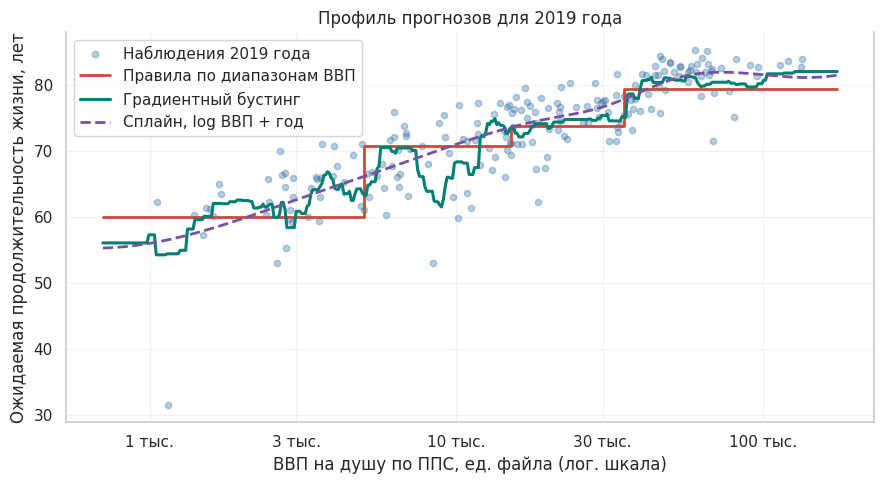

In [30]:
# Профили прогнозов при разных значениях ВВП
plot_year = 2019
gdp_grid = np.geomspace(train.gdp_ppp.min(), train.gdp_ppp.max(), 400)
model_inputs = pd.DataFrame({
    "gdp_ppp": gdp_grid,
    "log_gdp": np.log(gdp_grid),
    "year": plot_year,
})

fig, axis = plt.subplots(figsize=(9, 5))
axis.scatter(
    snapshot["gdp_ppp"], snapshot["life"],
    s=20, alpha=0.33, color=BLUE, label=f"Наблюдения {plot_year} года",
)
axis.step(
    gdp_grid, manual_model.predict(model_inputs),
    where="post", color=RED, label="Правила по диапазонам ВВП", linewidth=2,
)
axis.plot(gdp_grid, winner.predict(model_inputs), color=GREEN, label=winner_name, linewidth=2.2)

smooth_name = "Сплайн, log ВВП + год"
if winner_name != smooth_name:
    axis.plot(
        gdp_grid, fitted_models[smooth_name].predict(model_inputs),
        color="#7752A1", linestyle="--", label=smooth_name, linewidth=2,
    )

axis.set(ylabel=LIFE_LABEL, title=f"Профиль прогнозов для {plot_year} года")
format_gdp_axis(axis)
axis.legend()
show_figure(fig)

In [31]:
# Ручной ввод ВВП и года
def predict_life(gdp_ppp, year):
    """Оценка ожидаемой продолжительности жизни при известном ВВП."""
    gdp_ppp = float(gdp_ppp)
    year = float(year)

    if not np.isfinite(gdp_ppp) or gdp_ppp <= 0:
        raise ValueError("Укажите конечный положительный ВВП на душу по ППС.")
    if not year.is_integer() or not data["year"].min() <= year <= data["year"].max():
        raise ValueError(f"Укажите целый год из диапазона {data.year.min()}–{data.year.max()}.")
    if not train["gdp_ppp"].min() <= gdp_ppp <= train["gdp_ppp"].max():
        raise ValueError("ВВП за пределами диапазона обучающей выборки.")

    inputs = pd.DataFrame({
        "gdp_ppp": [gdp_ppp],
        "log_gdp": [np.log(gdp_ppp)],
        "year": [int(year)],
    })
    return float(winner.predict(inputs)[0])


# Измените значения для ручного ввода.
example_gdp = 15000
example_year = 2019

estimate = predict_life(example_gdp, example_year)
print(f"При ВВП {example_gdp:g} и годе {example_year} оценка — {estimate:.2f} года.")

При ВВП 15000 и годе 2019 оценка — 73.47 года.


In [32]:
# Итог по моделям
print("Итог")
for part in tests:
    part_scores = scores.loc[scores["Проверка"] == part].set_index("Модель")
    result = part_scores.loc[winner_name]
    print(
        f"{part}. MAE выбранной модели {result['MAE, лет']:.2f} года, "
        f"RMSE {result['RMSE, лет']:.2f}, R² {result['R²']:.3f}. "
        f"MAE правил {part_scores.at['Диапазоны ВВП', 'MAE, лет']:.2f}, "
        f"MAE медианы {part_scores.at['Медиана', 'MAE, лет']:.2f}."
    )
    lowest_mae = part_scores["MAE, лет"].idxmin()
    if lowest_mae != winner_name:
        print(
            "На этой выборке минимальная наблюдаемая MAE у модели "
            f"«{lowest_mae}» ({part_scores.at[lowest_mae, 'MAE, лет']:.2f} года)."
        )

print("MAE по годам для выбранной модели")
display(year_mae.round(2))

Итог
Знакомые экономики. MAE выбранной модели 2.91 года, RMSE 3.78, R² 0.743. MAE правил 3.49, MAE медианы 6.27.
Отложенные экономики. MAE выбранной модели 3.85 года, RMSE 4.90, R² 0.675. MAE правил 3.58, MAE медианы 6.74.
На этой выборке минимальная наблюдаемая MAE у модели «Сплайн, log ВВП + год» (3.23 года).
MAE по годам для выбранной модели


Проверка,Знакомые экономики,Отложенные экономики
year,,
2016,2.76,3.74
2017,2.89,3.93
2018,2.94,3.73
2019,3.08,4.32
2020,2.89,3.53


In [33]:
# Проверка эффекта логарифмирования при одинаковом признаке года
linear_names = ["Линейная, ВВП + год", "Линейная, log ВВП + год"]
linear_scores = scores.loc[scores["Модель"].isin(linear_names)]
print("Сравнение двух линейных моделей с годом. Меняется только вид признака ВВП.")
display(linear_scores.pivot(index="Модель", columns="Проверка", values="MAE, лет").round(3))

Сравнение двух линейных моделей с годом. Меняется только вид признака ВВП.


Проверка,Знакомые экономики,Отложенные экономики
Модель,,
"Линейная, log ВВП + год",2.989,3.285
"Линейная, ВВП + год",4.128,4.450
